# Sprint 1 — Notebook 1: tempo de processamento do Pix **antes** da intervenção

**Variável:** `Tempo_processamento_seg` — tempo de processamento de um pagamento via Pix no checkout do e-commerce
**Unidade de medida:** segundos
**Dados:** Planilha 1 — 300 observações coletadas **antes** da inclusão da etapa extra de validação antifraude.

Este notebook responde às Questões 1 a 6 e segue os comandos do material "Python - Distribuição Normal". A análise da Planilha 2 (depois da intervenção) e a comparação entre os cenários (Questões 7 e 8) estão em `Notebook_2_Analise_depois_da_Intervencao.ipynb`.

## 1. Importar as bibliotecas

In [1]:
# Importa o pandas para ler a planilha e manipular os dados em tabela.
import pandas as pd
# Importa o numpy para operações numéricas.
import numpy as np
# Importa o math para funções matemáticas.
import math
# Importa o seaborn para construir o histograma e o boxplot.
import seaborn as sns
# Importa o pyplot do matplotlib para títulos, rótulos e exibição dos gráficos.
import matplotlib.pyplot as plt
# Importa o statsmodels para construir o gráfico Q-Q.
import statsmodels.api as sm
# Importa a distribuição normal (norm) do scipy para probabilidades e quantis.
from scipy.stats import norm
# Importa o pylab para exibir o gráfico Q-Q.
import pylab

## 2. Definir as variáveis `arquivo` e `coluna`

In [2]:
# Define a variável arquivo com o caminho da Planilha 1 (dados antes da intervenção).
arquivo = "../Refs/Planilha 1 - TEMPO PAGAMENTO PIX.xlsx"
# Define a variável coluna com o nome da coluna analisada (tempo em segundos).
coluna = "Tempo_processamento_seg"

## 3. Leitura do arquivo de dados — Planilha 1 (antes da intervenção)

In [3]:
# Lê a planilha com pd.read_excel e armazena os dados na variável df.
df=pd.read_excel(arquivo)
# Exibe a tabela armazenada.
df

,Tempo_processamento_seg
0,1.47
1,1.48
2,1.61
3,1.67
4,1.69
...,...
295,3.40
296,3.40
297,3.41
298,3.42


## Questão 1 — Situação-problema

**Contexto:** uma empresa de e-commerce oferece o Pix como uma das principais formas de pagamento no checkout. Como o Pix é percebido pelo cliente como um pagamento instantâneo, a confirmação rápida da transação faz parte da experiência de compra: o pedido só é liberado depois que o pagamento é processado.

**Apresentação do problema:** com o crescimento das vendas, a empresa passou a registrar mais tentativas de fraude em pagamentos via Pix (contas de terceiros, golpes e pedidos contestados). A área de risco recomendou incluir uma etapa extra de validação antifraude antes da confirmação do pagamento. Antes de qualquer mudança, porém, a empresa precisa conhecer como o tempo de processamento do Pix se comporta hoje, para depois avaliar se ele continuará aceitável.

**Identificação de uma possível causa:** o tempo de processamento depende de cada etapa executada entre o clique em "pagar" e a confirmação, como a comunicação com o provedor de pagamentos e as validações internas. Qualquer etapa adicional, como uma análise antifraude, tende a acrescentar latência ao processamento.

**Importância da variável:** o tempo de processamento (em segundos) afeta diretamente a conversão do checkout. Tempos altos geram a sensação de que o pagamento travou, aumentam o abandono de carrinho, as tentativas de pagamento duplicado e os chamados ao atendimento. Por isso ele é o indicador usado para decidir se a operação do Pix está saudável.

**Valores de referência e justificativa:**

- **Faixa ideal: entre 2 e 3 segundos.** É onde se concentra a maior parte das transações atuais da Planilha 1 (média de cerca de 2,5 segundos e cerca de 89% das transações em até 3 segundos) e corresponde à percepção de pagamento instantâneo que o cliente espera do Pix.
- **Limite tolerável: até 6 segundos.** O grupo definiu esse limite como o dobro do teto da faixa ideal: acima dele a espera passa a ser perceptível como demora e o cliente tende a desistir ou repetir o pagamento.

Esses valores foram definidos pelo grupo a partir do comportamento observado na Planilha 1 e do contexto do processo; eles norteiam as Questões 5, 7.4 e 8. Diante disso, a empresa coletou o tempo de processamento de 300 pagamentos via Pix antes da intervenção, que formam a Planilha 1.

## Questão 2 — Representação gráfica dos dados anteriores à intervenção

### 4. Gerar o histograma e o boxplot para variável contínua

#### 4.1 Representação do histograma com a curva normal

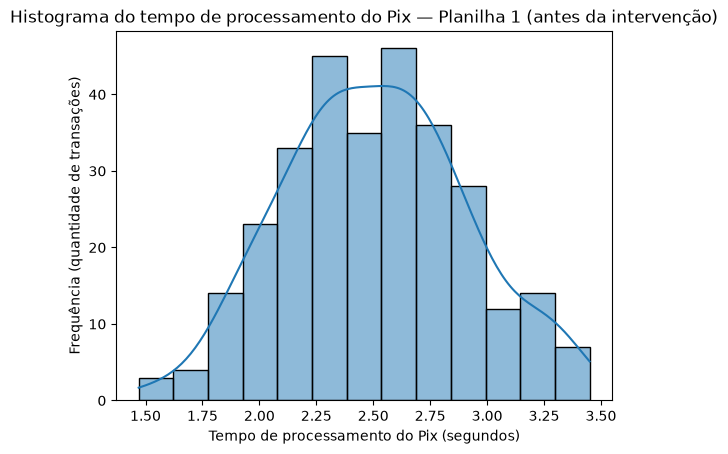

In [4]:
# Plota o histograma com a curva de densidade (kde), como no item 4.1 do material.
sns.histplot(data=df[coluna],kde=True)
# Define o título do gráfico, identificando a variável e o momento da coleta.
plt.title("Histograma do tempo de processamento do Pix — Planilha 1 (antes da intervenção)")
# Identifica a variável e a unidade de medida no eixo x.
plt.xlabel("Tempo de processamento do Pix (segundos)")
# Identifica o eixo y como a frequência (quantidade de transações).
plt.ylabel("Frequência (quantidade de transações)")
# Exibe o gráfico.
plt.show()

#### 4.2 Boxplot

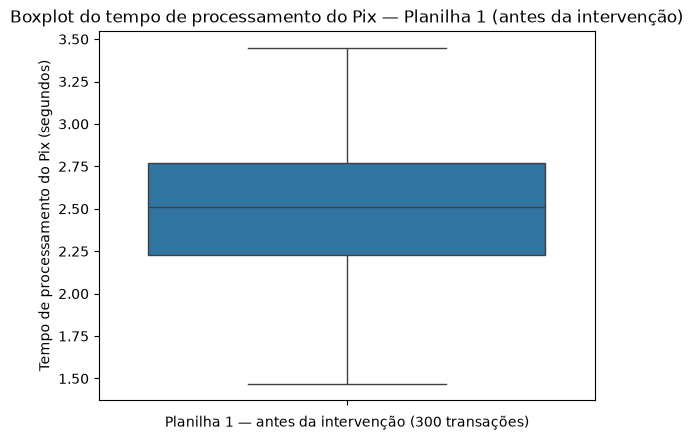

In [5]:
# Plota o boxplot, como no item 4.2 do material.
sns.boxplot(data=df[coluna])
# Define o título do gráfico, identificando a variável e o momento da coleta.
plt.title("Boxplot do tempo de processamento do Pix — Planilha 1 (antes da intervenção)")
# Identifica no eixo x a planilha representada.
plt.xlabel("Planilha 1 — antes da intervenção (300 transações)")
# Identifica a variável e a unidade de medida no eixo y.
plt.ylabel("Tempo de processamento do Pix (segundos)")
# Exibe o gráfico.
plt.show()

## Questão 3 — Média e desvio-padrão dos dados anteriores à intervenção

### 5. Cálculo da Média, Mediana e do Desvio Padrão

#### Média

In [6]:
# mean -> calcula a média aritmética dos tempos (arredondada em 2 casas).
media = round(df[coluna].mean(), 2)
# Mostra a média com a unidade de medida.
print(f'Média antes da intervenção: {media} segundos')

Média antes da intervenção: 2.51 segundos


#### Mediana

In [7]:
# median -> calcula a mediana (valor central dos tempos ordenados).
mediana = round(df[coluna].median(), 2)
# Mostra a mediana com a unidade de medida.
print(f'Mediana antes da intervenção: {mediana} segundos')

Mediana antes da intervenção: 2.51 segundos


#### Desvio-padrão amostral

In [8]:
# std -> calcula o desvio-padrão amostral (divisor n - 1), arredondado em 2 casas.
dpad = round(df[coluna].std(), 2)
# Mostra o desvio-padrão com a unidade de medida.
print(f'Desvio-padrão antes da intervenção: {dpad} segundos')

Desvio-padrão antes da intervenção: 0.4 segundos


## Questão 4 — Testes de normalidade

### 6. Testes de Normalidade

#### 6.1 Análise do Histograma

6.1.1 Verificar único pico e analisar a proximidade dele com a média e a mediana (que devem ser próximas).

6.1.2 Calcular a proporção de dados nos intervalos de um, dois e três desvios-padrão em torno da média e comparar com a regra empírica 68%-95%-99%.

##### Definindo os limites de cada intervalo

In [9]:
# Limite inferior do intervalo de 1 desvio-padrão (média - dpad).
limite_inf1dp=round(media-dpad,2)
# Limite inferior do intervalo de 2 desvios-padrão (média - 2 dpad).
limite_inf2dp=round(media-2*dpad,2)
# Limite inferior do intervalo de 3 desvios-padrão (média - 3 dpad).
limite_inf3dp=round(media-3*dpad,2)
# Limite superior do intervalo de 1 desvio-padrão (média + dpad).
limite_sup1dp=round(media+dpad,2)
# Limite superior do intervalo de 2 desvios-padrão (média + 2 dpad).
limite_sup2dp=round(media+2*dpad,2)
# Limite superior do intervalo de 3 desvios-padrão (média + 3 dpad).
limite_sup3dp=round(media+3*dpad,2)
# Mostra os intervalos em segundos.
print(f'±1 desvio-padrão: [{limite_inf1dp}, {limite_sup1dp}] segundos')
# Mostra o intervalo de 2 desvios-padrão em segundos.
print(f'±2 desvios-padrão: [{limite_inf2dp}, {limite_sup2dp}] segundos')
# Mostra o intervalo de 3 desvios-padrão em segundos.
print(f'±3 desvios-padrão: [{limite_inf3dp}, {limite_sup3dp}] segundos')

±1 desvio-padrão: [2.11, 2.91] segundos
±2 desvios-padrão: [1.71, 3.31] segundos
±3 desvios-padrão: [1.31, 3.71] segundos


##### Calculando a quantidade de dados em cada intervalo

In [10]:
# Conta os tempos dentro de ±1 desvio-padrão.
quantidade_1dp=sum(i>=limite_inf1dp and i<= limite_sup1dp for i in df[coluna].sort_values())
# Conta os tempos dentro de ±2 desvios-padrão.
quantidade_2dp=sum(i>=limite_inf2dp and i<= limite_sup2dp for i in df[coluna].sort_values())
# Conta os tempos dentro de ±3 desvios-padrão.
quantidade_3dp=sum(i>=limite_inf3dp and i<= limite_sup3dp for i in df[coluna].sort_values())
# Mostra as quantidades de observações em cada intervalo.
print(f'Observações em ±1 dp: {quantidade_1dp} | ±2 dp: {quantidade_2dp} | ±3 dp: {quantidade_3dp}')

Observações em ±1 dp: 204 | ±2 dp: 288 | ±3 dp: 300


##### Calculando a proporção de dados em cada intervalo

In [11]:
#Porcentagem entre + - 1 desvio padrão
porcentagem1 = round((quantidade_1dp/len(df[coluna]))*100,2)
#Porcentagem entre + - 2 desvios padrão
porcentagem2 = round((quantidade_2dp/len(df[coluna]))*100,2)
#Porcentagem entre + - 3 desvios padrão
porcentagem3 = round((quantidade_3dp/len(df[coluna]))*100,2)
# Compara as porcentagens observadas com a regra empírica.
print(f'±1 desvio-padrão: {porcentagem1}% (regra empírica ≈ 68%)')
# Compara a porcentagem em ±2 desvios-padrão com 95%.
print(f'±2 desvios-padrão: {porcentagem2}% (regra empírica ≈ 95%)')
# Compara a porcentagem em ±3 desvios-padrão com 99%.
print(f'±3 desvios-padrão: {porcentagem3}% (regra empírica ≈ 99%)')

±1 desvio-padrão: 68.0% (regra empírica ≈ 68%)
±2 desvios-padrão: 96.0% (regra empírica ≈ 95%)
±3 desvios-padrão: 100.0% (regra empírica ≈ 99%)


**Interpretação breve:** O histograma apresenta um único pico, localizado perto de 2,5 segundos, praticamente sobre a média e a mediana (ambas de 2,51 segundos), e a curva de densidade tem formato de sino. As proporções observadas — 68%, 96% e 100% dentro de 1, 2 e 3 desvios-padrão — ficam próximas da regra empírica (68%, 95% e 99%). **Conclusão do teste:** pelo histograma, os dados da Planilha 1 são compatíveis com uma distribuição aproximadamente normal.

#### 6.2 Análise do Boxplot

Verificar a simetria `Q2 − Q1 = Q3 − Q2`, usando os comandos de quartis do Projeto 1.

In [12]:
# quantile -> calcula o primeiro quartil (25% dos tempos abaixo dele).
Q1 = df[coluna].quantile(q=0.25)
# Calcula o segundo quartil, que é a mediana.
Q2 = df[coluna].quantile(q=0.50)
# Calcula o terceiro quartil (75% dos tempos abaixo dele).
Q3 = df[coluna].quantile(q=0.75)
# Distância da metade inferior da caixa.
Q2_menos_Q1 = round(Q2 - Q1, 2)
# Distância da metade superior da caixa.
Q3_menos_Q2 = round(Q3 - Q2, 2)
# Mostra os quartis e as distâncias em segundos.
print(f'Q1: {Q1} segundos\nQ2: {Q2} segundos\nQ3: {Q3} segundos')
# Mostra as duas distâncias para comparar a simetria.
print(f'Q2 - Q1 = {Q2_menos_Q1} segundos | Q3 - Q2 = {Q3_menos_Q2} segundos')

Q1: 2.23 segundos
Q2: 2.51 segundos
Q3: 2.7725 segundos
Q2 - Q1 = 0.28 segundos | Q3 - Q2 = 0.26 segundos


**Interpretação breve:** As duas metades da caixa do boxplot medem aproximadamente 0,28 s (Q2 − Q1) e 0,26 s (Q3 − Q2), e os bigodes têm comprimentos parecidos. Como as distâncias são próximas, os quartis indicam simetria aproximada em torno da mediana. **Conclusão do teste:** pelo boxplot, os dados são compatíveis com uma distribuição aproximadamente normal.

#### 6.3 Gráfico Q-Q

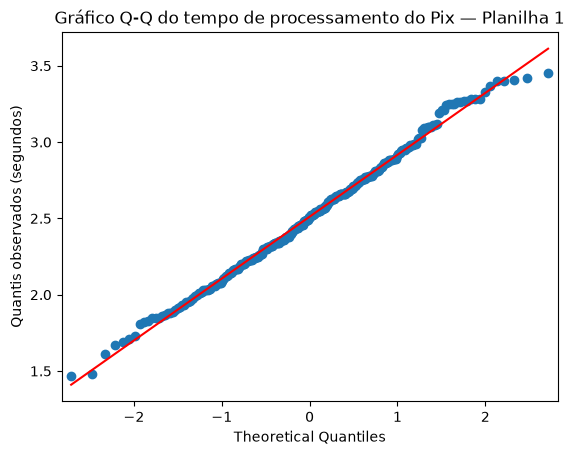

In [13]:
# Constrói o gráfico Q-Q com a reta de referência ajustada (line = 'r').
sm.qqplot(df[coluna], line = 'r')
# Define o título do gráfico.
plt.title("Gráfico Q-Q do tempo de processamento do Pix — Planilha 1")
# Identifica o eixo y como os quantis observados, em segundos.
plt.ylabel("Quantis observados (segundos)")
# Exibe o gráfico.
pylab.show()

**Interpretação breve:** Os pontos do gráfico Q-Q acompanham de perto a reta de referência em quase toda a extensão, com pequenos afastamentos apenas nas caudas, comportamento esperado em amostras reais. **Conclusão do teste:** pelo gráfico Q-Q, os dados são compatíveis com uma distribuição aproximadamente normal.

#### Conclusão geral da Questão 4

Os três testes apontam na mesma direção: histograma com pico único próximo da média e da mediana e proporções próximas da regra empírica, boxplot aproximadamente simétrico e gráfico Q-Q próximo da reta. Portanto, o tempo de processamento do Pix na Planilha 1 pode ser modelado por uma **distribuição normal** com a média e o desvio-padrão obtidos na Questão 3, e esse modelo é usado nas Questões 5 e 6.

## Questão 5 — Probabilidade em um intervalo

### 7. Calculando a Probabilidade em Intervalos

Nos comandos abaixo: `loc` = média e `scale` = desvio-padrão (valores da Questão 3).

**Intervalo escolhido:** de 2 a 3 segundos.

**Justificativa:** é a faixa ideal definida na Questão 1, que corresponde à percepção de pagamento instantâneo do Pix. Calcular a probabilidade de um pagamento cair nessa faixa mostra quanto da operação atual, antes da etapa antifraude, já entrega a experiência ideal.

In [14]:
# P(x>=2 e x<=3)
probabilidade_intervalo = norm.cdf(3,loc=media,scale=dpad).round(4)-norm.cdf(2,loc=media,scale=dpad).round(4)
# Mostra a probabilidade em decimal e em porcentagem.
print(f'P(2 <= x <= 3) = {probabilidade_intervalo:.4f} ({probabilidade_intervalo:.2%})')

P(2 <= x <= 3) = 0.7885 (78.85%)


**Interpretação breve:** Pela distribuição normal com média de 2,51 segundos e desvio-padrão de 0,40 segundo, a probabilidade de um pagamento via Pix ser processado entre 2 e 3 segundos é de 78,85%. Ou seja, antes da etapa antifraude, cerca de 4 em cada 5 pagamentos são confirmados dentro da faixa ideal, o que mostra que a operação atual entrega a experiência de pagamento instantâneo na grande maioria dos casos.

## Questão 6 — Valores máximos e mínimos que limitam determinados intervalos

- Valor máximo para estar entre os **20% menores** tempos: `norm.ppf(0.20, ...)`.
- Valor mínimo para estar entre os **30% maiores** tempos: como a função usa a probabilidade acumulada, procuram-se os 70% menores, `norm.ppf(0.70, ...)`.

In [15]:
# P(x<=a)=0,20 Valor de x para os 20% menores
valor_maximo_20_menores = norm.ppf(0.20,loc=media,scale=dpad).round(2)
# P(x>=a)=0,30  Valor de x para os 30% maiores
# Como usa-se a f.d.p. acumulada temos que procurar os 70% menores
valor_minimo_30_maiores = norm.ppf(0.70,loc=media,scale=dpad).round(2)
# Mostra os dois limites em segundos.
print(f'Limite máximo dos 20% menores: {valor_maximo_20_menores} segundos')
# Mostra o limite mínimo dos 30% maiores em segundos.
print(f'Limite mínimo dos 30% maiores: {valor_minimo_30_maiores} segundos')

Limite máximo dos 20% menores: 2.17 segundos
Limite mínimo dos 30% maiores: 2.72 segundos


**Interpretação breve:** Pela distribuição normal, os 20% pagamentos via Pix processados mais rapidamente levam no máximo cerca de 2,17 segundos, e os 30% pagamentos mais lentos levam no mínimo cerca de 2,72 segundos. Mesmo esse grupo mais lento continua, em sua maior parte, dentro da faixa ideal de 2 a 3 segundos e muito abaixo do limite tolerável de 6 segundos.

## Síntese da Planilha 1 (referência para o Notebook 2)

- Média de 2,51 segundos e desvio-padrão de 0,40 segundo.
- Distribuição aproximadamente normal (Questão 4).
- Probabilidade de 78,85% de um pagamento ficar na faixa ideal de 2 a 3 segundos.
- Esses resultados são o cenário **antes** da intervenção e serão comparados com a Planilha 2 no Notebook 2.